In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import plotly.express as px 
import plotly.io as pio
from unidecode import unidecode
from scipy.stats import chi2_contingency
from itertools import combinations
import prince
import importlib.metadata
pio.renderers.default = 'vscode'

## ETL

In [2]:
# Leitura arquivo csv
df_mp_original = pd.read_csv("../data/biodiesel-materia-prima.csv")

In [3]:
# Verificando as primeiras 5 linhas do dataframe
df_mp_original.head()


,Mês/Ano,Região,Estado,Produto,Quantidade (m³)
0,08/2023,CENTRO OESTE,Goiás,ÁCIDO GRAXO DE ÓLEO DE SOJA,652
1,08/2023,CENTRO OESTE,Mato Grosso,ÁCIDO GRAXO DE ÓLEO DE SOJA,956
2,08/2023,SUDESTE,São Paulo,ÁCIDO GRAXO DE ÓLEO DE SOJA,511
3,08/2023,CENTRO OESTE,Goiás,GORDURA BOVINA,6595
4,08/2023,CENTRO OESTE,Mato Grosso,GORDURA BOVINA,447


In [4]:
# Verificando as info do dataframe
df_mp_original.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4745 entries, 0 to 4744
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Mês/Ano          4745 non-null   object
 1   Região           4745 non-null   object
 2   Estado           4745 non-null   object
 3   Produto          4745 non-null   object
 4   Quantidade (m³)  4745 non-null   int64 
dtypes: int64(1), object(4)
memory usage: 185.5+ KB


In [5]:

#Verificando se as variaveis estao na mesma escala 
df_mp_original.describe()

,Quantidade (m³)
count,4745.000000
mean,8411.538462
std,19047.244330
min,0.000000
25%,322.000000
50%,1849.000000
75%,6518.000000
max,150567.000000


In [6]:
# Verificando quais as colunas do dataframe
df_mp_original.columns

Index(['Mês/Ano', 'Região', 'Estado', 'Produto', 'Quantidade (m³)'], dtype='object')

In [7]:
# Verificando quant. de linhas e colunas
df_mp_original.shape

(4745, 5)

In [8]:
# Verificando quantos dados vazios em cada coluna
df_mp_original.isnull().sum()

Mês/Ano            0
Região             0
Estado             0
Produto            0
Quantidade (m³)    0
dtype: int64

In [9]:
# Padronizando str em minúscula
df_mp_original.columns = df_mp_original.columns.str.lower()
df_mp_original['região'] = df_mp_original['região'].str.lower()
df_mp_original['produto'] = df_mp_original['produto'].str.lower()
df_mp_original['estado'] = df_mp_original['estado'].str.lower()
df_mp_original.head()

,mês/ano,região,estado,produto,quantidade (m³)
0,08/2023,centro oeste,goiás,ácido graxo de óleo de soja,652
1,08/2023,centro oeste,mato grosso,ácido graxo de óleo de soja,956
2,08/2023,sudeste,são paulo,ácido graxo de óleo de soja,511
3,08/2023,centro oeste,goiás,gordura bovina,6595
4,08/2023,centro oeste,mato grosso,gordura bovina,447


In [10]:
# Removendo acentuação

df_mp_original = df_mp_original.map(lambda x: unidecode(x) if isinstance(x, str) else x)
df_mp_original.head()


df_mp_original.columns = [unidecode(str(col)) for col in df_mp_original.columns]
df_mp_original.head()


df_mp_original.rename(columns={"quantidade (m3)": "quantidade_m3"}, inplace=True)

df_mp_original.head()

,mes/ano,regiao,estado,produto,quantidade_m3
0,08/2023,centro oeste,goias,acido graxo de oleo de soja,652
1,08/2023,centro oeste,mato grosso,acido graxo de oleo de soja,956
2,08/2023,sudeste,sao paulo,acido graxo de oleo de soja,511
3,08/2023,centro oeste,goias,gordura bovina,6595
4,08/2023,centro oeste,mato grosso,gordura bovina,447


In [11]:
# Separando mês e ano em duas colunas
df_mp_original['mes'] = pd.to_datetime(df_mp_original['mes/ano'], format='%m/%Y').dt.month
df_mp_original['ano'] = pd.to_datetime(df_mp_original['mes/ano'], format='%m/%Y').dt.year
df_mp_original.head()

,mes/ano,regiao,estado,produto,quantidade_m3,mes,ano
0,08/2023,centro oeste,goias,acido graxo de oleo de soja,652,8,2023
1,08/2023,centro oeste,mato grosso,acido graxo de oleo de soja,956,8,2023
2,08/2023,sudeste,sao paulo,acido graxo de oleo de soja,511,8,2023
3,08/2023,centro oeste,goias,gordura bovina,6595,8,2023
4,08/2023,centro oeste,mato grosso,gordura bovina,447,8,2023


## Clusterização

### Dispersão dos dados

In [12]:
# Histograma
fig_hist = px.histogram(
    df_mp_original,
    x='quantidade_m3',
    nbins=30
)

fig_hist.write_html('hist_quantidade_m3_30.html')

# Boxplot
fig_box = px.box(
    df_mp_original,
    y='quantidade_m3',
    title='Boxplot da Quantidade (m³)'
)

fig_box.write_html('boxplot_quantidade_m3.html')
# Obs: Tanto pelo hisograma quanto pelo boxplot, verifiquei escala divergente entre os dados



In [13]:
# Padronização pelo Z score para adequação de escala
col_quant = df_mp_original[['quantidade_m3']] # Selecionei apenas coluna quantitativa e mantive como df [[]] 

type(col_quant)

df_mp_pad = pd.DataFrame(
            zscore(col_quant, ddof=1),
            columns = ['quantidade_m3'],
            index = df_mp_original.index
)

df_mp_pad.head()

print(round(df_mp_pad.mean(), 2))
print(round(df_mp_pad.std(), 2))

quantidade_m3    0.0
dtype: float64
quantidade_m3    1.0
dtype: float64


### Clusterização pelo método k-means

In [14]:
# Identificação da quantidade de clusters

# Método Elbow para identificação do nº de clusters
# Observar o "cotovelo" para verificar n de clusters. Quanto menor o WCSS, mais prox as obs estao do seu proprio centroide
elbow = []
K = range(1,6)  # você pode aumentar se quiser

for k in K:
    kmeansElbow = KMeans(n_clusters=k, init='k-means++', random_state=100)
    kmeansElbow.fit(df_mp_pad[['quantidade_m3']])
    elbow.append(kmeansElbow.inertia_)

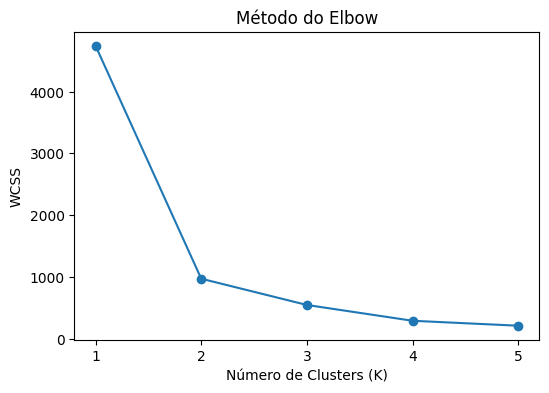

In [15]:
# Plotando
plt.figure(figsize=(6,4), dpi=100)
plt.plot(K, elbow, marker='o')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('WCSS')
plt.title('Método do Elbow')
plt.xticks(K)

plt.savefig('../outputs/kmeans_elbow.png', dpi=600, bbox_inches='tight')
plt.show()

In [16]:
# Método Silhueta para identificação do nº de clusters
# Coeficiente silhueta - valores próximos de 1 indicativos de melhor separação e coesão entre os grupos. Maior = melhor.
silhouette_scores = []
K = range(2,6)

for k in K:
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=100)
    labels = kmeans.fit_predict(df_mp_pad[['quantidade_m3']])
    score = silhouette_score(df_mp_pad[['quantidade_m3']], labels)
    silhouette_scores.append(score)

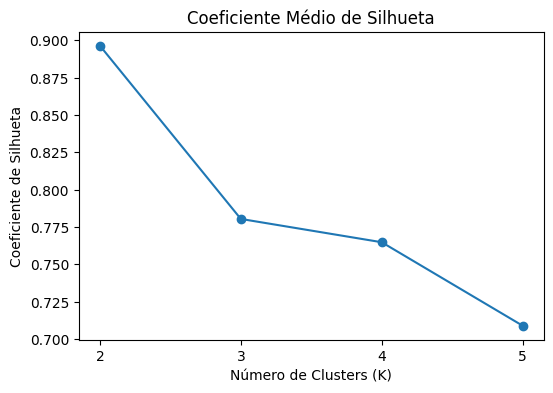

In [17]:
# Plot
plt.figure(figsize=(6,4), dpi=100)
plt.plot(K, silhouette_scores, marker='o')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Coeficiente de Silhueta')
plt.title('Coeficiente Médio de Silhueta')
plt.xticks(K)

plt.savefig('../outputs/kmeans_silhueta.png', dpi=600, bbox_inches='tight')
plt.show()

In [18]:
# Criando modelo Kmeans com 2 clusters
kmeans = KMeans(n_clusters=2, init='k-means++', random_state=100) # Escolhi 2 clusters, k-means++ já pula para resultados iniciais melhores, 100 garante reprodutibilidade
clusters_kmeans = kmeans.fit_predict(df_mp_pad[['quantidade_m3']]) # Calcula o centroide e atribui obs ao centroide mais proximo. fit ajusta o modelo aos dados e predict retorna o cluster de cada observação

# Gerando variável para identificar clusters gerados
df_mp_original['cluster_kmeans'] = pd.Categorical(clusters_kmeans)

df_mp_original['cluster_kmeans'].value_counts()

# Obs: Cluster 1 é composto por 266 observações, enquanto cluster 0 contém 4.479 observações

cluster_kmeans
0    4479
1     266
Name: count, dtype: int64

In [19]:
# Identificando Centróides em Z-score (para registro do funcionamento interno do modelo)
cent_kmeans = pd.DataFrame(
    kmeans.cluster_centers_,
    columns = ['quantidade_m3']
 )

cent_kmeans.index.name = 'cluster'
cent_kmeans

# Centróides nos valores originais (para interpretação)
cent_kmeans_original = df_mp_original.groupby('cluster_kmeans', observed=True)['quantidade_m3'].mean().reset_index()
cent_kmeans_original.columns = ['cluster', 'quantidade_m3']
cent_kmeans_original

,cluster,quantidade_m3
0,0,4271.727841
1,1,78119.101504


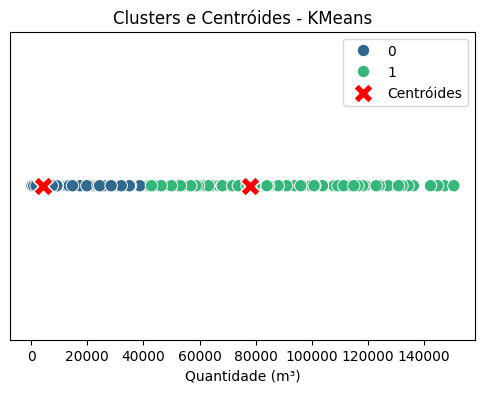

In [20]:
# Plotando Scatter em linha horizontal (apenas 1 variável quantidade_m3)
plt.figure(figsize=(6,4), dpi=100)
sns.scatterplot(
    data=df_mp_original,
    x='quantidade_m3',
    y=[0]*len(df_mp_original),
    hue='cluster_kmeans',
    palette='viridis',
    s=80
)
sns.scatterplot(
    data=cent_kmeans_original,
    x='quantidade_m3',
    y=[0]*len(cent_kmeans_original),
    color='red',
    marker='X',
    s=200,
    label='Centróides'
)
plt.yticks([])
plt.xlabel('Quantidade (m³)')
plt.title('Clusters e Centróides - KMeans')
plt.legend()

plt.savefig('../outputs/kmeans_centroides.png', dpi=600, bbox_inches='tight')
plt.show()

In [21]:
#       Análise Cluster 1 (266 observacoes) 
df_soja_cluster1_k = df_mp_original [
    (df_mp_original['cluster_kmeans'] == 1) &
    (df_mp_original['produto'] == 'oleo de soja (glycine max)')
]

df_soja_cluster1_k.shape[0]

df_soja_cluster1_k['quantidade_m3'].describe()
df_mp_original['quantidade_m3'].describe(percentiles=[0.90,0.95,0.99])

# Obs: Produto oleo de soja é predominante no cluster 1, com 265 observações, representando 99,62% dos dados.
# O metodo K means apresenta mesmo comportamento na criação dos clusters que o metodo Hierarquico Aglomerativo.
# Visto que, o cluster 1 apresenta os valores extremos de produção.

count      4745.000000
mean       8411.538462
std       19047.244330
min           0.000000
50%        1849.000000
90%       19735.600000
95%       48720.200000
99%       99693.360000
max      150567.000000
Name: quantidade_m3, dtype: float64

In [22]:

df_mp_original.head(100)

,mes/ano,regiao,estado,produto,quantidade_m3,mes,ano,cluster_kmeans
0,08/2023,centro oeste,goias,acido graxo de oleo de soja,652,8,2023,0
1,08/2023,centro oeste,mato grosso,acido graxo de oleo de soja,956,8,2023,0
2,08/2023,sudeste,sao paulo,acido graxo de oleo de soja,511,8,2023,0
3,08/2023,centro oeste,goias,gordura bovina,6595,8,2023,0
4,08/2023,centro oeste,mato grosso,gordura bovina,447,8,2023,0
...,...,...,...,...,...,...,...,...
95,07/2023,nordeste,bahia,oleo de palma/dende (elaeis guineensis ou elae...,2712,7,2023,0
96,07/2023,norte,para,oleo de palma/dende (elaeis guineensis ou elae...,12314,7,2023,0
97,07/2023,norte,rondonia,oleo de palma/dende (elaeis guineensis ou elae...,64,7,2023,0
98,07/2023,norte,para,oleo de palmiste,12,7,2023,0


In [23]:
df_regiao  = pd.DataFrame(df_mp_original['regiao'].unique(),  columns=['regiao'])
df_estado  = pd.DataFrame(df_mp_original['estado'].unique(),  columns=['estado'])
df_produto = pd.DataFrame(df_mp_original['produto'].unique(), columns=['produto'])
df_ano     = pd.DataFrame(df_mp_original['ano'].unique(),     columns=['ano'])

In [24]:
print(
    len(df_regiao), 
    len(df_estado), 
    len(df_produto), 
    len(df_ano)
    )

# Aqui temos 4 variáveis qualitativas, em que cada uma tem um número diferente de categorias.
# Região: 5 categorias, Estado: 14 categorias, Produto: 14 categorias, Ano: 7 categorias. Totalizando 40 categorias (J).

5 14 14 7


In [25]:
df_produto

,produto
0,acido graxo de oleo de soja
1,gordura bovina
2,gordura de frango
3,gordura de porco
4,oleo de algodao (gossypium hirsut)
5,oleo de colza/canola (bressica campestris)
6,oleo de fritura usado
7,oleo de milho
8,oleo de palma/dende (elaeis guineensis ou elae...
9,oleo de soja (glycine max)


## ACM - Análise de Correspondência Múltipla

### Associação entre variáveis - teste qui²

In [26]:
#Verificando se há associação entre as variáveis categóricas utilizando teste qui-quadrado de independência

variaveis = ['regiao', 'estado', 'produto', 'ano']

resultados = []

for var1, var2 in combinations(variaveis, 2):
    tabela = pd.crosstab(df_mp_original[var1], df_mp_original[var2])
    chi2, p, gl, _ = chi2_contingency(tabela)
    resultados.append({
        'Par': f"{var1.capitalize()} x {var2.capitalize()}",
        'Chi²': round(chi2, 4),
        'GL': gl,
        'p-valor': round(p, 4),
        'Associação': '✅ Sim' if p < 0.05 else '❌ Não'
    })

df_chi2 = pd.DataFrame(resultados)
df_chi2

# Quanto maior o valor de chi2 (qui2), maior a associação entre as varáveis.
# Quanto maior o GL (graus de liberdade), maior a complexidade da tabela de contingência.
# O p-valor indica a significância estatística da associação. Valores menores que 0.05 indicam associação significativa entre as variáveis.
# Nesse caso, todas as associações entre as variáveis são significativas, indicando que há uma relação entre elas.
# Por exemplo, região e estado estão fortemente associadas, com chi bem elevado, o que é esperado, já que os estados estão agrupados por região.

,Par,Chi²,GL,p-valor,Associação
0,Regiao x Estado,18980.0000,52,0.0,✅ Sim
1,Regiao x Produto,1228.6644,52,0.0,✅ Sim
2,Regiao x Ano,127.5767,24,0.0,✅ Sim
3,Estado x Produto,2683.5026,169,0.0,✅ Sim
4,Estado x Ano,495.0862,78,0.0,✅ Sim
5,Produto x Ano,159.7475,78,0.0,✅ Sim


### ACM com Método Matriz de Burt

In [27]:
# ── 1. Selecionar apenas as variáveis categóricas de interesse ──────────────
# A Matriz de Burt é construída a partir da matriz binária (Z),
# calculada internamente pelo prince com base nessas colunas.

variaveis_acm = ['regiao', 'estado', 'produto', 'ano']

df_acm = df_mp_original[variaveis_acm].copy()

In [28]:
# ── 2. Ajustar o modelo ACM com Matriz de Burt ─────────────────────────────
# n_components: número de dimensões a extrair.
#   → limite teórico: max_dims = J - K = 40 - 4 = 36 dimensões úteis.
#   → usamos 36 para garantir que todos os autovalores corrigidos estejam
#     disponíveis — necessário para aplicar o critério de Greenacre no bloco 3.
# correction='benzecri': aplica a correção de Greenacre na inércia
#   → sem isso, os autovalores são o quadrado dos da matriz binária,
#     distorcendo os % explicados por cada dimensão.
# random_state: garante reprodutibilidade

acm = prince.MCA(
    n_components=36,
    n_iter=10, # número de iterações para convergência estimado em 10, mas pode ser ajustado conforme necessário
    correction='benzecri', # disponível a partir da versão 0.13+ com esse nome
    random_state=42
)

acm = acm.fit(df_acm)

In [42]:
# ── 3. Variância explicada por dimensão ────────────────────────────────────
# Critério de Greenacre para retenção de dimensões:
#   → reter apenas as dimensões cujo autovalor corrigido seja MAIOR
#     que a média dos autovalores corrigidos (análogo ao critério de Kaiser na PCA).
#   → dimensões abaixo da média capturam variação da mesma ordem que ruído
#     estrutural da Matriz de Burt — não devem ser interpretadas.
#
# Atributos disponíveis nessa versão do prince (0.17.0):
#   eigenvalues_: autovalores de cada dimensão
#   percentage_of_variance_: % de inércia explicada por cada dimensão
#   cumulative_percentage_of_variance_: % acumulado de inércia explicada

eigenvalues = acm.eigenvalues_
media_eigenvalues = np.mean(eigenvalues)
dims_retidas = int(np.sum(eigenvalues > media_eigenvalues))

print(f"Média dos autovalores corrigidos: {media_eigenvalues:.4f}")
print(f"Dimensões a reter (critério Greenacre): {dims_retidas}\n")

df_inertia = pd.DataFrame({
    'Dimensão': [f'Dim {i+1}' for i in range(len(eigenvalues))],
    'Autovalor': eigenvalues.round(4),
    'Inércia explicada (%)': acm.percentage_of_variance_.round(2),
    'Inércia acumulada (%)': acm.cumulative_percentage_of_variance_.round(2),
    # Sinaliza quais dimensões superam a média — critério de Greenacre
    'Reter?': ['✅' if e > media_eigenvalues else '❌' for e in eigenvalues]
})

print(df_inertia)

acm.scree_plot()
plt.savefig('../outputs/acm_scree_plot.png', dpi=600, bbox_inches='tight')
plt.show()
# acm.scree_plot() — disponível nativamente nessa versão do prince.
# Plota o gráfico de cotovelo (scree plot) com os autovalores em ordem decrescente.
# Útil para visualizar onde a queda se estabiliza e confirmar dims_retidas.
acm.scree_plot()



Média dos autovalores corrigidos: 0.0169
Dimensões a reter (critério Greenacre): 4

   Dimensão  Autovalor  Inércia explicada (%)  Inércia acumulada (%) Reter?
0     Dim 1     0.1768                  29.10                  29.10      ✅
1     Dim 2     0.1458                  24.00                  53.10      ✅
2     Dim 3     0.1244                  20.47                  73.57      ✅
3     Dim 4     0.1179                  19.41                  92.98      ✅
4     Dim 5     0.0115                   1.90                  94.89      ❌
5     Dim 6     0.0091                   1.49                  96.38      ❌
6     Dim 7     0.0081                   1.33                  97.70      ❌
7     Dim 8     0.0049                   0.80                  98.50      ❌
8     Dim 9     0.0033                   0.54                  99.04      ❌
9    Dim 10     0.0029                   0.48                  99.52      ❌
10   Dim 11     0.0014                   0.22                  99.75      ❌
11  

<Figure size 640x480 with 0 Axes>

alt.Chart(...)

In [30]:
# ── 4. Coordenadas das categorias no mapa fatorial ─────────────────────────
# column_coordinates_: posição de cada categoria nas dimensões extraídas.
# Filtramos para exibir apenas as dimensões retidas pelo critério de Greenacre,
# evitando poluir a saída com dimensões que capturam ruído.

coords = acm.column_coordinates(df_acm)

# Seleciona apenas as colunas das dimensões retidas (0 até dims_retidas - 1)
coords_retidas = coords.iloc[:, :dims_retidas]
coords_retidas.columns = [f'Dim {i+1}' for i in range(dims_retidas)]

print(coords_retidas.round(3))

                                                    Dim 1  Dim 2  Dim 3  Dim 4
regiao__centro oeste                                0.273  1.329 -0.517  0.483
regiao__nordeste                                    1.582 -0.450 -0.531 -2.272
regiao__norte                                       1.926 -1.380  1.044  1.887
regiao__sudeste                                    -0.715  0.103  1.374 -0.436
regiao__sul                                        -0.871 -0.995 -1.026  0.240
estado__bahia                                       1.581 -0.447 -0.527 -2.268
estado__goias                                       0.314  1.326 -0.480  0.489
estado__mato grosso                                 0.241  1.439 -0.553  0.484
estado__mato grosso do sul                          0.227  1.119 -0.543  0.465
estado__minas gerais                               -0.754  0.025  1.325 -0.440
estado__para                                        2.351 -1.705  1.099  2.140
estado__parana                                     -

In [31]:
# ── 5. Mapa fatorial — (Dim1×Dim2) ────────────────────────────────
# Cobre 53.10% da inércia total corrigida.
# O modelo foi ajustado com todas as variáveis (regiao, estado, produto, ano),
# mas a visualização filtra apenas regiao e produto para facilitar a leitura.
# Ano e estado continuam influenciando as coordenadas — apenas não são plotados.

variaveis_labels = []
for var in variaveis_acm:
    categorias = df_acm[var].unique()
    variaveis_labels.extend([var] * len(categorias))

coords_retidas['variavel'] = variaveis_labels

# Remove o prefixo "variavel__" do índice — a cor já identifica a variável
coords_retidas.index = [
    idx.split('__')[-1] if '__' in idx else idx
    for idx in coords_retidas.index
]

# Exibe rótulo apenas para categorias distantes da origem (mais discriminantes)
# Ajuste o limiar conforme necessário para reduzir sobreposição
limiar_rotulo = 0.5

coords_retidas['rotulo'] = [
    label if abs(row['Dim 1']) > limiar_rotulo or abs(row['Dim 2']) > limiar_rotulo else ''
    for label, row in coords_retidas.iterrows()
]

# Filtra apenas as variáveis de interesse para o mapa
# O modelo continua usando todas as variáveis — apenas a visualização é filtrada
variaveis_plot = ['regiao', 'produto']
coords_retidas_plot = coords_retidas[coords_retidas['variavel'].isin(variaveis_plot)]

fig = px.scatter(
    coords_retidas_plot,
    x='Dim 1',
    y='Dim 2',
    color='variavel',
    hover_name=coords_retidas_plot.index,
    title=f'ACM — Mapa Fatorial | Dim 1 × Dim 2 '
          f'({acm.percentage_of_variance_[0]:.1f}% + '
          f'{acm.percentage_of_variance_[1]:.1f}% = 53.10%)',
    labels={'Dim 1': f'Dim 1 ({acm.percentage_of_variance_[0]:.1f}%)',
            'Dim 2': f'Dim 2 ({acm.percentage_of_variance_[1]:.1f}%)'},
    width=650,
    height=520
)

fig.update_traces(
    marker=dict(size=10)
)

fig.add_hline(y=0, line_dash='dash', line_color='gray', line_width=0.8)
fig.add_vline(x=0, line_dash='dash', line_color='gray', line_width=0.8)
fig.update_layout(
    plot_bgcolor='white',
    xaxis=dict(showgrid=True, gridcolor='lightgray'),
    yaxis=dict(showgrid=True, gridcolor='lightgray')
)

fig.show()
pio.write_html(fig, '../outputs/acm_mapa1_dim1_dim2.html')

/tmp/ipykernel_11183/3733072181.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  coords_retidas['variavel'] = variaveis_labels
/tmp/ipykernel_11183/3733072181.py:24: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  coords_retidas['rotulo'] = [


In [32]:
# ── 5.1 Análise tabular das coordenadas fatoriais ────────────────────────────
# Complementa o mapa fatorial: identifica quais categorias são mais
# discriminantes (dist_origem alta) e em qual quadrante cada uma se posiciona.
# - Linhas de 'ano' removidas (todas no centro — sem poder discriminante)
# - Ordenado por dist_origem decrescente para destacar os pontos mais extremos

df_analise = coords_retidas[['Dim 1', 'Dim 2']].copy()

# 1a. Identificar a variável de origem (regiao, estado, produto, ano)
#     já está disponível em coords_retidas — apenas reutilizamos
df_analise['variavel'] = coords_retidas['variavel']

# 1b. Calcular distância euclidiana da origem
df_analise['dist_origem'] = np.sqrt(df_analise['Dim 1']**2 + df_analise['Dim 2']**2)

# 1c. Identificar quadrante
def get_quadrante(x, y, tol=0.3):
    x_centro = abs(x) < tol
    y_centro = abs(y) < tol
    if x_centro and y_centro:
        return 'centro'
    if x_centro:
        return '+0' if y > 0 else '-0'
    if y_centro:
        return '0+' if x > 0 else '0-'
    if x > 0 and y > 0: return '++'
    if x > 0 and y < 0: return '+-'
    if x < 0 and y > 0: return '-+'
    return '--'

df_analise['quadrante'] = df_analise.apply(
    lambda r: get_quadrante(r['Dim 1'], r['Dim 2']), axis=1
)

# 1d. Remover ano (sem poder discriminante — todos ficaram no centro)
df_analise = df_analise[df_analise['variavel'] != 'ano']

# Exibir ordenado por distância (categorias mais extremas primeiro)
df_analise.sort_values('dist_origem', ascending=False).round(3)

,Dim 1,Dim 2,variavel,dist_origem,quadrante
para,2.351,-1.705,estado,2.904,+-
oleo de girassol (hellanthus annus),0.474,2.542,produto,2.586,++
rondonia,2.026,-1.431,estado,2.480,+-
norte,1.926,-1.380,regiao,2.369,+-
oleo de colza/canola (bressica campestris),-1.445,-1.817,produto,2.322,--
tocantins,1.777,-1.281,estado,2.191,+-
acido graxo de oleo de soja,0.152,1.932,produto,1.938,+0
oleo de palma/dende (elaeis guineensis ou elaeis o,1.636,-0.408,produto,1.686,+-
piaui,1.586,-0.469,estado,1.654,+-
nordeste,1.582,-0.450,regiao,1.645,+-


In [33]:
# ── 5.2 Tabela de categorias por quadrante ───────────────────────────────────

ordem_quadrantes = ['++', '+-', '-+', '--', '+0', '0+', '-0', '0-', 'centro']

def tabela_por_quadrante(df, caption):
    df_sorted = (
        df
        .assign(quadrante=pd.Categorical(df['quadrante'], categories=ordem_quadrantes, ordered=True))
        .sort_values(['quadrante', 'dist_origem'], ascending=[True, False])
    )
    grupos = {
        q: df_sorted.loc[df_sorted['quadrante'] == q].index.tolist()
        for q in ordem_quadrantes
        if q in df_sorted['quadrante'].values
    }
    tabela = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in grupos.items()]))
    tabela.index = range(1, len(tabela) + 1)
    return tabela.fillna('').style.set_caption(caption)

# Visão resumida — espelha o mapa (regiao + produto)
variaveis_mapa = ['regiao', 'produto']
df_analise_mapa = df_analise[df_analise['variavel'].isin(variaveis_mapa)]
display(tabela_por_quadrante(df_analise_mapa, 'Categorias por Quadrante — Regiões e Produtos | Dim 1 × Dim 2'))

# Visão completa — inclui estado para aprofundamento
display(tabela_por_quadrante(df_analise, 'Categorias por Quadrante — Incluindo Estados | Dim 1 × Dim 2'))

,++,+-,-+,--,+0,0-,centro
1,oleo de girassol (hellanthus annus),norte,acido graxo de oleo de palma / dende,oleo de colza/canola (bressica campestris),acido graxo de oleo de soja,gordura de porco,gordura bovina
2,oleo de algodao (gossypium hirsut),oleo de palma/dende (elaeis guineensis ou elaeis o,oleo de milho,sul,centro oeste,gordura de frango,oleo de fritura usado
3,,nordeste,,,,sudeste,oleo de soja (glycine max)
4,,oleo de palmiste,,,,,outros materiais graxos


,++,+-,-+,--,+0,0-,centro
1,oleo de girassol (hellanthus annus),para,acido graxo de oleo de palma / dende,oleo de colza/canola (bressica campestris),acido graxo de oleo de soja,gordura de porco,gordura bovina
2,goias,rondonia,oleo de milho,rio grande do sul,mato grosso,gordura de frango,oleo de fritura usado
3,oleo de algodao (gossypium hirsut),norte,,sul,centro oeste,rio de janeiro,oleo de soja (glycine max)
4,,tocantins,,santa catarina,mato grosso do sul,minas gerais,outros materiais graxos
5,,oleo de palma/dende (elaeis guineensis ou elaeis o,,parana,,sudeste,
6,,piaui,,,,sao paulo,
7,,nordeste,,,,,
8,,bahia,,,,,
9,,oleo de palmiste,,,,,


In [34]:
# ── 6. Mapa fatorial 2 — Dim3 × Dim4 (39.88% da inércia) ─────────────────
# Complementa o Mapa 1 — revela estruturas que Dim1 e Dim2 não capturam.
# Interpretação independente do Mapa 1: não compare coordenadas entre os dois mapas.

fig2 = px.scatter(
    coords_retidas_plot,
    x='Dim 3',
    y='Dim 4',
    color='variavel',
    hover_name=coords_retidas_plot.index,
    title=f'ACM — Mapa Fatorial 2 | Dim 3 × Dim 4 '
          f'({acm.percentage_of_variance_[2]:.1f}% + '
          f'{acm.percentage_of_variance_[3]:.1f}% = 39.88%)',
    labels={
        'Dim 3': f'Dim 3 ({acm.percentage_of_variance_[2]:.1f}%)',
        'Dim 4': f'Dim 4 ({acm.percentage_of_variance_[3]:.1f}%)'
    },
    width=650,
    height=520
)

fig2.update_traces(
    marker=dict(size=10)
)

fig2.add_hline(y=0, line_dash='dash', line_color='gray', line_width=0.8)
fig2.add_vline(x=0, line_dash='dash', line_color='gray', line_width=0.8)
fig2.update_layout(
    plot_bgcolor='white',
    xaxis=dict(showgrid=True, gridcolor='lightgray'),
    yaxis=dict(showgrid=True, gridcolor='lightgray')
)
fig2.show()
pio.write_html(fig2, '../outputs/acm_mapa2_dim3_dim4.html')

In [35]:
# ── 6.1 Análise tabular das coordenadas fatoriais — Dim 3 × Dim 4 ────────────

df_analise_34 = coords_retidas[['Dim 3', 'Dim 4']].copy()

# Reaproveita a coluna variavel já atribuída
df_analise_34['variavel'] = coords_retidas['variavel']

# Distância euclidiana da origem no plano Dim3 × Dim4
df_analise_34['dist_origem'] = np.sqrt(df_analise_34['Dim 3']**2 + df_analise_34['Dim 4']**2)

# Quadrante baseado em Dim3 e Dim4
df_analise_34['quadrante'] = df_analise_34.apply(
    lambda r: get_quadrante(r['Dim 3'], r['Dim 4']), axis=1
)

# Remove ano (sem poder discriminante)
df_analise_34 = df_analise_34[df_analise_34['variavel'] != 'ano']

# Exibir ordenado por distância
df_analise_34.sort_values('dist_origem', ascending=False).round(3)

,Dim 3,Dim 4,variavel,dist_origem,quadrante
acido graxo de oleo de palma / dende,2.479,-0.737,produto,2.586,+-
para,1.099,2.140,estado,2.405,++
piaui,-0.562,-2.305,estado,2.372,--
nordeste,-0.531,-2.272,regiao,2.333,--
bahia,-0.527,-2.268,estado,2.328,--
oleo de palmiste,1.385,1.801,produto,2.272,++
rondonia,1.049,1.977,estado,2.238,++
norte,1.044,1.887,regiao,2.156,++
oleo de colza/canola (bressica campestris),-2.031,0.480,produto,2.087,-+
tocantins,1.029,1.782,estado,2.058,++


In [36]:
# ── 6.2 Tabela de categorias por quadrante — Dim 3 × Dim 4 ───────────────────

ordem_quadrantes = ['++', '+-', '-+', '--', '+0', '0+', '-0', '0-', 'centro']

def tabela_por_quadrante(df, caption):
    df_sorted = (
        df
        .assign(quadrante=pd.Categorical(df['quadrante'], categories=ordem_quadrantes, ordered=True))
        .sort_values(['quadrante', 'dist_origem'], ascending=[True, False])
    )
    grupos = {
        q: df_sorted.loc[df_sorted['quadrante'] == q].index.tolist()
        for q in ordem_quadrantes
        if q in df_sorted['quadrante'].values
    }
    tabela = pd.DataFrame(dict([(k, pd.Series(v)) for k, v in grupos.items()]))
    tabela.index = range(1, len(tabela) + 1)
    return tabela.fillna('').style.set_caption(caption)

# Visão resumida — espelha o mapa (regiao + produto)
variaveis_mapa = ['regiao', 'produto']
df_analise_34_mapa = df_analise_34[df_analise_34['variavel'].isin(variaveis_mapa)]
display(tabela_por_quadrante(df_analise_34_mapa, 'Categorias por Quadrante — Regiões e Produtos | Dim 3 × Dim 4'))

# Visão completa — inclui estado
display(tabela_por_quadrante(df_analise_34, 'Categorias por Quadrante — Incluindo Estados | Dim 3 × Dim 4'))

,++,+-,-+,--,+0,0-,centro
1,oleo de palmiste,acido graxo de oleo de palma / dende,oleo de colza/canola (bressica campestris),nordeste,acido graxo de oleo de soja,sul,oleo de milho
2,norte,sudeste,oleo de girassol (hellanthus annus),oleo de algodao (gossypium hirsut),,,oleo de palma/dende (elaeis guineensis ou elaeis o
3,,,centro oeste,,,,gordura bovina
4,,,,,,,oleo de soja (glycine max)
5,,,,,,,outros materiais graxos
6,,,,,,,oleo de fritura usado
7,,,,,,,gordura de porco
8,,,,,,,gordura de frango


,++,+-,-+,--,+0,0-,centro
1,para,acido graxo de oleo de palma / dende,oleo de colza/canola (bressica campestris),piaui,acido graxo de oleo de soja,rio grande do sul,oleo de milho
2,oleo de palmiste,sao paulo,oleo de girassol (hellanthus annus),nordeste,,santa catarina,oleo de palma/dende (elaeis guineensis ou elaeis o
3,rondonia,sudeste,mato grosso,bahia,,sul,gordura bovina
4,norte,rio de janeiro,mato grosso do sul,oleo de algodao (gossypium hirsut),,parana,oleo de soja (glycine max)
5,tocantins,minas gerais,centro oeste,,,,outros materiais graxos
6,,,goias,,,,oleo de fritura usado
7,,,,,,,gordura de porco
8,,,,,,,gordura de frango


In [37]:
# ── 7 Proporção do cluster 1 por categoria ─────────────────────────────────
# Para cada categoria de cada variável, calcula a % de obs no cluster 1

prop_cluster1 = {}

for var in ['regiao', 'estado', 'produto']:  # adicionado estado
    for cat in df_mp_original[var].unique():
        mask = df_mp_original[var] == cat
        total = mask.sum()
        cluster1 = (df_mp_original.loc[mask, 'cluster_kmeans'] == 1).sum()
        prop_cluster1[cat] = round(cluster1 / total * 100, 1)

# Filtra para o mapa — agora com estado incluído
variaveis_plot_cluster = ['regiao', 'estado', 'produto']
coords_retidas_plot_cluster = coords_retidas[
    coords_retidas['variavel'].isin(variaveis_plot_cluster)
].copy()

coords_retidas_plot_cluster['pct_cluster1'] = coords_retidas_plot_cluster.index.map(prop_cluster1)

In [38]:
# ── 7.1 Mapa fatorial colorido pelo cluster ───────────────────────────────────

limiar_rotulo_cluster = 0.8

coords_retidas_plot_cluster['rotulo'] = [
    label if abs(row['Dim 1']) > limiar_rotulo_cluster or abs(row['Dim 2']) > limiar_rotulo_cluster else ''
    for label, row in coords_retidas_plot_cluster.iterrows()
]

# Garante tamanho mínimo visível — soma base para que nenhum ponto suma
coords_retidas_plot_cluster['tamanho'] = coords_retidas_plot_cluster['pct_cluster1'] + 8

fig3 = px.scatter(
    coords_retidas_plot_cluster,
    x='Dim 1',
    y='Dim 2',
    color='pct_cluster1',
    size='tamanho',
    size_max=30,
    color_continuous_scale='RdYlGn',
    hover_name=coords_retidas_plot_cluster.index,
    hover_data={'pct_cluster1': ':.1f', 'variavel': True, 'tamanho': False, 'Dim 1': ':.3f', 'Dim 2': ':.3f'},
    title='ACM — Perfil de Matéria-Prima × Volume de Produção | Dim 1 × Dim 2',
    labels={
        'Dim 1': f'Dim 1 ({acm.percentage_of_variance_[0]:.1f}%)',
        'Dim 2': f'Dim 2 ({acm.percentage_of_variance_[1]:.1f}%)',
        'pct_cluster1': '% grandes produtores'
    },
    width=650,
    height=520
)

fig3.update_traces(
    marker=dict(size=10)
)

fig3.add_hline(y=0, line_dash='dash', line_color='gray', line_width=0.8)
fig3.add_vline(x=0, line_dash='dash', line_color='gray', line_width=0.8)
fig3.update_layout(
    plot_bgcolor='white',
    xaxis=dict(showgrid=True, gridcolor='lightgray'),
    yaxis=dict(showgrid=True, gridcolor='lightgray')
)
fig3.show()
pio.write_html(fig3, '../outputs/acm_mapa_cluster_mp_volume.html')


In [39]:
for var, titulo in [('produto', 'Produto'), ('estado', 'Estado')]:
    df_var = coords_retidas_plot_cluster[coords_retidas_plot_cluster['variavel'] == var]

    fig4 = px.scatter(
        df_var,
        x='Dim 1',
        y='Dim 2',
        color='pct_cluster1',
        size='tamanho',
        size_max=30,
        color_continuous_scale='RdYlGn',
        hover_name=df_var.index,
        hover_data={'pct_cluster1': ':.1f', 'variavel': False, 'tamanho': False},
        title=f'ACM × Cluster — {titulo} | Dim 1 × Dim 2',
        labels={
            'Dim 1': f'Dim 1 ({acm.percentage_of_variance_[0]:.1f}%)',
            'Dim 2': f'Dim 2 ({acm.percentage_of_variance_[1]:.1f}%)',
            'pct_cluster1': '% grandes produtores'
        },
        width=700,
        height=520
    )
    fig4.add_hline(y=0, line_dash='dash', line_color='gray', line_width=0.8)
    fig4.add_vline(x=0, line_dash='dash', line_color='gray', line_width=0.8)
    fig4.update_layout(
        plot_bgcolor='white',
        xaxis=dict(showgrid=True, gridcolor='lightgray'),
        yaxis=dict(showgrid=True, gridcolor='lightgray')
    )
    fig4.show()
    pio.write_html(fig4, f'../outputs/acm_mapa_fatorial_cluster_{var}.html')

In [40]:
tabela_produto = (
    coords_retidas_plot_cluster[coords_retidas_plot_cluster['variavel'] == 'produto'][['pct_cluster1']]
    .sort_values('pct_cluster1', ascending=False)
    .reset_index()
    .rename(columns={'index': 'Produto', 'pct_cluster1': '% Grandes Produtores'})
)
tabela_produto

,Produto,% Grandes Produtores
0,oleo de soja (glycine max),29.6
1,oleo de milho,0.6
2,gordura bovina,0.0
3,gordura de frango,0.0
4,acido graxo de oleo de palma / dende,0.0
5,acido graxo de oleo de soja,0.0
6,oleo de algodao (gossypium hirsut),0.0
7,gordura de porco,0.0
8,oleo de fritura usado,0.0
9,oleo de colza/canola (bressica campestris),0.0


In [41]:
tabela_estado = (
    coords_retidas_plot_cluster[coords_retidas_plot_cluster['variavel'] == 'estado'][['pct_cluster1']]
    .sort_values('pct_cluster1', ascending=False)
    .reset_index()
    .rename(columns={'index': 'Estado', 'pct_cluster1': '% Grandes Produtores'})
)
tabela_estado

,Estado,% Grandes Produtores
0,mato grosso,15.0
1,rio grande do sul,14.9
2,goias,11.7
3,parana,7.8
4,bahia,0.0
5,mato grosso do sul,0.0
6,para,0.0
7,minas gerais,0.0
8,piaui,0.0
9,rio de janeiro,0.0


## Conclusão

A clusterização via KMeans identificou dois grupos distintos: um cluster majoritário com mais de 4.700 observações de volumes regulares de produção, e um cluster minoritário composto pelos maiores volumes registrados, formado em 99,62% por óleo de soja.

A ACM ampliou essa visão ao incorporar as variáveis qualitativas. Com 53,1% de inércia explicada pelas duas primeiras dimensões, identificou-se um padrão geográfico claro na escolha da matéria-prima: a Região Sul associada ao óleo de colza/canola e o estado de Goiás ao óleo de girassol e algodão. As dimensões 3 e 4 (39,88% de inércia adicional) complementaram essa visão revelando que os estados do Norte e Tocantins associam-se ao óleo de palma/dendê, enquanto Piauí e Bahia associam-se ao óleo de algodão.

Três grupos de matérias-primas emergiram: as com associação regional forte, o óleo de soja com dominância volumétrica concentrada no Sul e Centro-Oeste (29,6% dos grandes produtores), e gordura bovina, óleo de fritura usado e outros materiais graxos sem padrão regional definido, por serem subprodutos disponíveis em todo o território nacional.

Os estados com maior concentração de grandes volumes foram Rio Grande do Sul (15,0%), Mato Grosso (14,9%), Goiás (11,7%) e Paraná (7,8%).

As técnicas se mostraram complementares: o KMeans evidenciou a assimetria dos volumes, enquanto a ACM revelou o padrão regional subjacente — coerente com a geografia agrícola brasileira.